# Analyse exploratoire : UNSW-NB15

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path.cwd() / "data"
if not DATA_DIR.exists():
    DATA_DIR = Path.cwd().parent / "data"
TRAIN_PATH = DATA_DIR / "UNSW_NB15_training-set.csv"
TEST_PATH = DATA_DIR / "UNSW_NB15_testing-set.csv"

# configuration du thème
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)


## 1. Chargement et aperçu

In [2]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

display(pd.DataFrame({"train": train.shape, "test": test.shape}, index=["lignes", "colonnes"]))
print("Colonnes identiques :", train.columns.equals(test.columns))
display(train.dtypes.value_counts().rename("nombre de colonnes").to_frame())
print("\nColonnes de type str :")
print(train.select_dtypes(include=["object", "str"]).columns.tolist())

,train,test
lignes,175341,82332
colonnes,45,45


Colonnes identiques : True


,nombre de colonnes
int64,30
float64,11
str,4



Colonnes de type str :
['proto', 'service', 'state', 'attack_cat']


In [3]:
CATEGORICAL = train.select_dtypes(include=["object", "str"]).columns.drop("attack_cat").tolist()

In [4]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


In [5]:
train.drop(columns="id").describe().T

,count,mean,std,min,25%,50%,75%,max
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786140,3225.806520,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338870,879674.750000,8.888889e+07,5.988000e+09
dload,175341.0,6.712056e+05,2.421312e+06,0.0,0.000000,1447.022705,2.784487e+04,2.242273e+07


## 2. Qualité des données

'Aucune valeur manquante'

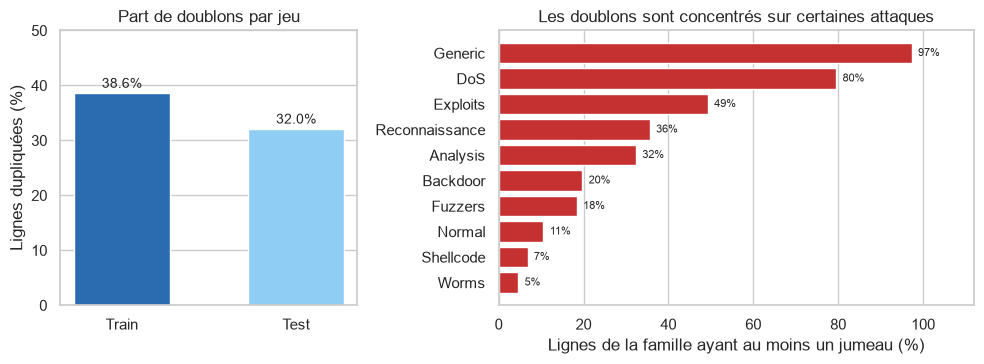

Colonnes constantes : []


,train,test
part de '-' (%),,
proto,0.00,0.00
service,53.71,57.27
state,0.00,0.00


In [6]:
missing = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})
display(missing[missing.any(axis=1)] if missing.any().any() else "Aucune valeur manquante")

duplicates = pd.DataFrame({
    "lignes_dupliquees": [
        train.drop(columns="id").duplicated().sum(),
        test.drop(columns="id").duplicated().sum(),
    ],
    "part": [
        train.drop(columns="id").duplicated().mean(),
        test.drop(columns="id").duplicated().mean(),
    ],
}, index=["train", "test"])

# Figure 1 : part de doublons par fichier et par famille d'attaque
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})

parts = duplicates["part"] * 100
bars = axes[0].bar(["Train", "Test"], parts, color=["#2b6cb0", "#90cdf4"], width=0.55)
for r, v in zip(bars, parts):
    axes[0].text(r.get_x() + r.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=10)
axes[0].set_ylim(0, 50)
axes[0].set_ylabel("Lignes dupliquées (%)")
axes[0].set_title("Part de doublons par jeu")
axes[0].grid(axis="x", visible=False)

# Un flux est jumelé s'il existe au moins une autre ligne identique
dup_any = pd.util.hash_pandas_object(train.drop(columns="id"), index=False).duplicated(keep=False)
dup_by_cat = train.assign(dup=dup_any).groupby("attack_cat")["dup"].mean().mul(100).sort_values()

bars = axes[1].barh(dup_by_cat.index, dup_by_cat.values, color="#c53030")
for r, v in zip(bars, dup_by_cat.values):
    axes[1].text(v + 1.5, r.get_y() + r.get_height() / 2, f"{v:.0f}%", va="center", fontsize=8)
axes[1].set_xlim(0, 112)
axes[1].set_xlabel("Lignes de la famille ayant au moins un jumeau (%)")
axes[1].set_title("Les doublons sont concentrés sur certaines attaques")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

constant_columns = train.columns[train.nunique() == 1].tolist()
print("Colonnes constantes :", constant_columns)

placeholder = pd.DataFrame({
    "train": {c: (train[c] == "-").mean() * 100 for c in CATEGORICAL},
    "test": {c: (test[c] == "-").mean() * 100 for c in CATEGORICAL},
}).round(2)
display(placeholder.rename_axis("part de '-' (%)"))

## 3. Variables cibles

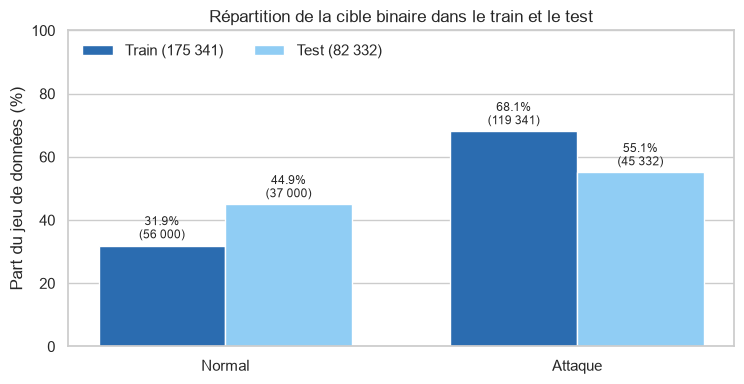

In [7]:
binary = pd.concat({"train": train["label"].value_counts(), "test": test["label"].value_counts()}, axis=1)
binary = binary.sort_index()
binary_pct = (binary / binary.sum() * 100).round(2)

# Figure 2 : cible binaire dans le train et dans le test
fig, ax = plt.subplots(figsize=(7.6, 4.0))
x = np.arange(2)
w = 0.36
b1 = ax.bar(x - w / 2, binary_pct["train"], w, label="Train (175 341)", color="#2b6cb0")
b2 = ax.bar(x + w / 2, binary_pct["test"], w, label="Test (82 332)", color="#90cdf4")
for bars, part, n in ((b1, binary_pct["train"], binary["train"]),
                      (b2, binary_pct["test"], binary["test"])):
    for r, v, c in zip(bars, part, n):
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 1.2,
                f"{v:.1f}%\n({c:,})".replace(",", " "),
                ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(x, ["Normal", "Attaque"])
ax.set_ylabel("Part du jeu de données (%)")
ax.set_ylim(0, 100)
ax.set_title("Répartition de la cible binaire dans le train et le test")
ax.legend(frameon=False, loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Ratio de déséquilibre (classe majoritaire / minoritaire) dans le train : 431


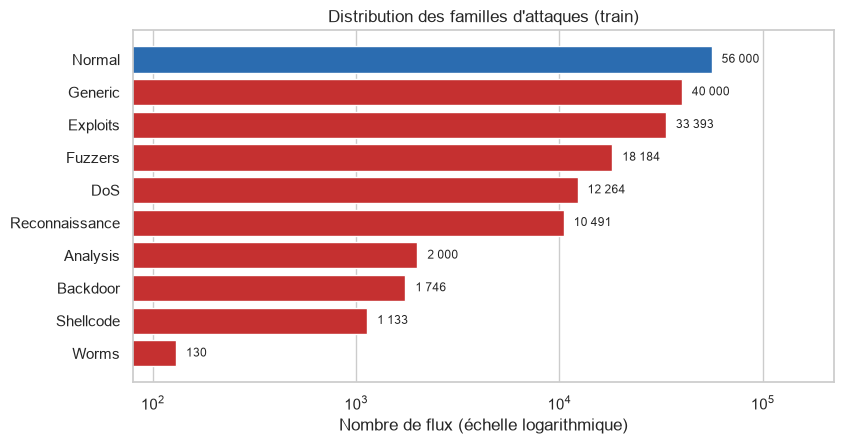

label,0,1
attack_cat,,
Analysis,0,2000
Backdoor,0,1746
DoS,0,12264
Exploits,0,33393
Fuzzers,0,18184
Generic,0,40000
Normal,56000,0
Reconnaissance,0,10491
Shellcode,0,1133


In [8]:
attack_counts = pd.concat({"train": train["attack_cat"].value_counts(), "test": test["attack_cat"].value_counts()}, axis=1)
attack_pct = (attack_counts / attack_counts.sum() * 100).round(2)

ratio = attack_counts["train"].max() / attack_counts["train"].min()
print(f"Ratio de déséquilibre (classe majoritaire / minoritaire) dans le train : {ratio:.0f}")

# Figure 3 : effectifs des familles dans le train (échelle logarithmique)
ac = train["attack_cat"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8.6, 4.6))
colors = ["#2b6cb0" if c == "Normal" else "#c53030" for c in ac.index]
bars = ax.barh(ac.index, ac.values, color=colors)
ax.set_xscale("log")
ax.set_xlim(80, ac.max() * 4)
ax.set_xlabel("Nombre de flux (échelle logarithmique)")
ax.set_title("Distribution des familles d'attaques (train)")
for r, v in zip(bars, ac.values):
    ax.text(v * 1.12, r.get_y() + r.get_height() / 2, f"{v:,}".replace(",", " "),
            va="center", fontsize=8.5)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

# Tableau final : effectifs par famille et par classe (train uniquement)
display(pd.crosstab(train["attack_cat"], train["label"]))

## 4. Variables catégorielles

In [9]:
unseen = {c: sorted(set(test[c]) - set(train[c])) for c in CATEGORICAL}
RARE_THRESHOLD = 0.01

rows = {}
for column in CATEGORICAL:
    freq = train[column].value_counts(normalize=True)
    rare = freq[freq < RARE_THRESHOLD]
    rows[column] = {
        "modalités train": len(freq),
        "modalités test": test[column].nunique(),
        "absentes du train": len(unseen[column]),
        f"rares (< {RARE_THRESHOLD:.0%})": len(rare),
        "% lignes couvertes par les rares": round(rare.sum() * 100, 2),
        "modalités pour 95 % des lignes": int((freq.cumsum() < 0.95).sum() + 1),
    }

summary = pd.DataFrame(rows).T
summary["% lignes couvertes par les rares"] = summary["% lignes couvertes par les rares"].round(2)
display(summary)
print("Modalités du test absentes du train :", unseen)

,modalités train,modalités test,absentes du train,rares (< 1%),% lignes couvertes par les rares,modalités pour 95 % des lignes
proto,133.0,131.0,0.0,128.0,8.31,43.0
service,13.0,13.0,0.0,7.0,1.53,5.0
state,9.0,7.0,2.0,5.0,0.06,3.0


Modalités du test absentes du train : {'proto': [], 'service': [], 'state': ['ACC', 'CLO']}


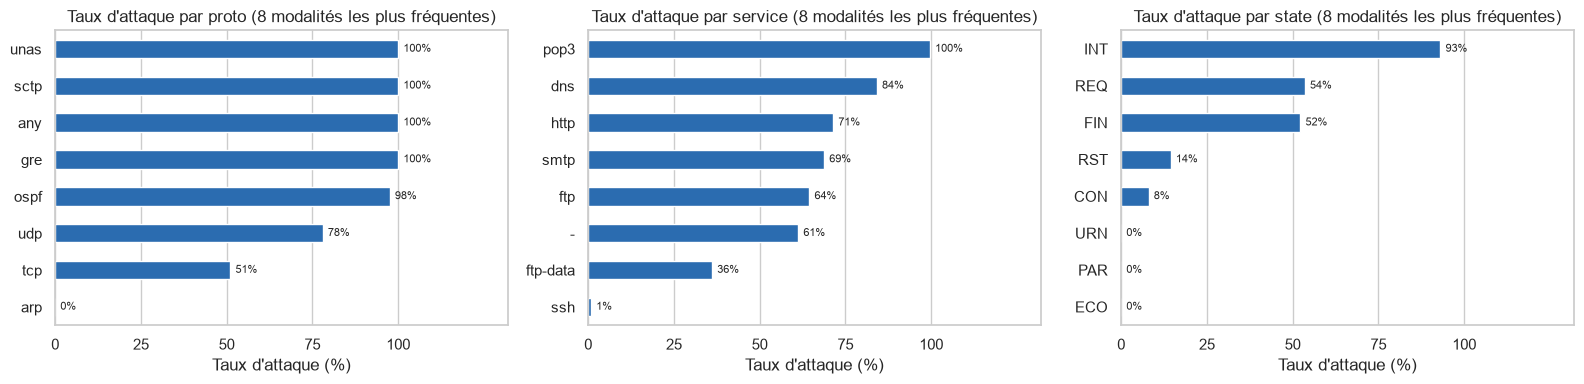

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(axes, CATEGORICAL):
    top = train[column].value_counts().head(8).index
    rate = train[train[column].isin(top)].groupby(column)["label"].mean().mul(100).sort_values()
    rate.plot.barh(ax=ax, color="#2b6cb0")
    ax.set_title(f"Taux d'attaque par {column} (8 modalités les plus fréquentes)")
    ax.set_xlabel("Taux d'attaque (%)")
    ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
    for i, v in enumerate(rate.values):
        ax.text(v + 1.5, i, f"{v:.0f}%", va="center", fontsize=8)
    ax.set_xlim(0, 132)
    ax.set_xticks([0, 25, 50, 75, 100])
plt.tight_layout()
plt.show()

## 5. Variables numériques

In [11]:
numeric_features = train.select_dtypes(include=np.number).columns.drop(["id", "label"])

skewness = pd.DataFrame({
    "skewness": train[numeric_features].skew(),
    "minimum": train[numeric_features].min(),
    "maximum": train[numeric_features].max(),
    "valeurs_uniques": train[numeric_features].nunique(),
}).sort_values("skewness", ascending=False)
skewness["tres_asymetrique"] = skewness["skewness"] > 2

display(skewness.round(3))

skewed_features = skewness.index[skewness["tres_asymetrique"]].tolist()
print(f"{len(skewed_features)} variables très asymétriques (skewness > 2) :")
print(skewed_features)

,skewness,minimum,maximum,valeurs_uniques,tres_asymetrique
trans_depth,167.336,0.0,1.720000e+02,11,True
response_body_len,76.340,0.0,6.558056e+06,2386,True
sbytes,45.303,28.0,1.296523e+07,7214,True
sloss,44.754,0.0,4.803000e+03,409,True
dloss,41.380,0.0,5.484000e+03,370,True
spkts,40.218,1.0,9.616000e+03,480,True
dbytes,39.761,0.0,1.465555e+07,6660,True
dpkts,36.764,0.0,1.097400e+04,443,True
dinpkt,29.680,0.0,5.671682e+04,74245,True
djit,29.544,0.0,2.893883e+05,76831,True


27 variables très asymétriques (skewness > 2) :
['trans_depth', 'response_body_len', 'sbytes', 'sloss', 'dloss', 'spkts', 'dbytes', 'dpkts', 'dinpkt', 'djit', 'ct_flw_http_mthd', 'sjit', 'ct_ftp_cmd', 'is_ftp_login', 'sload', 'sinpkt', 'is_sm_ips_ports', 'dur', 'synack', 'ackdat', 'dload', 'tcprtt', 'smean', 'rate', 'dmean', 'ct_src_dport_ltm', 'ct_dst_ltm']


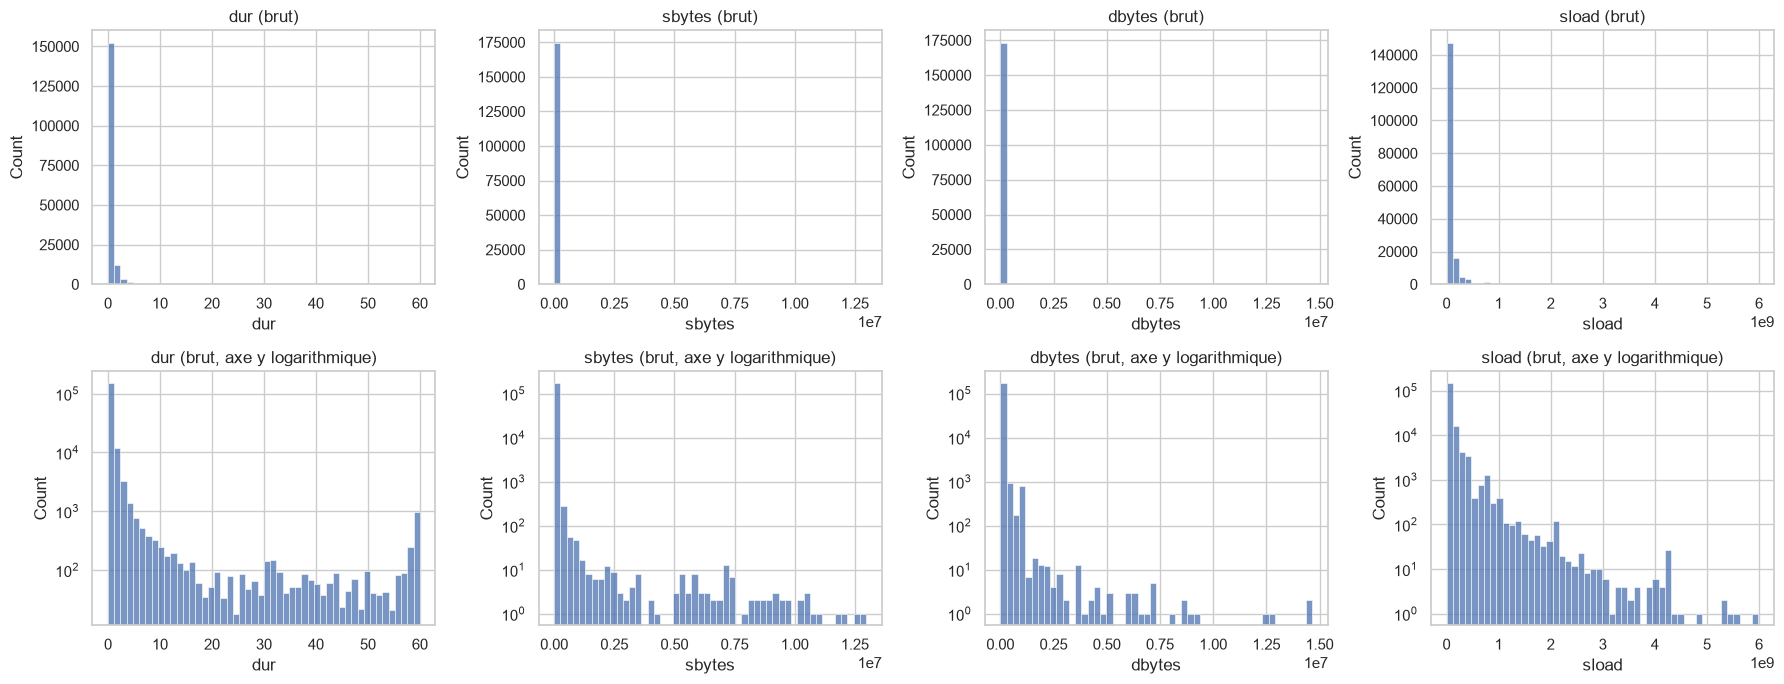

In [12]:
sample_features = ["dur", "sbytes", "dbytes", "sload"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, feature in enumerate(sample_features):
    sns.histplot(train[feature], bins=50, ax=axes[0, i])
    axes[0, i].set_title(f"{feature} (brut)")
    sns.histplot(train[feature], bins=50, ax=axes[1, i])
    axes[1, i].set_yscale("log")
    axes[1, i].set_title(f"{feature} (brut, axe y logarithmique)")
plt.tight_layout()
plt.show()

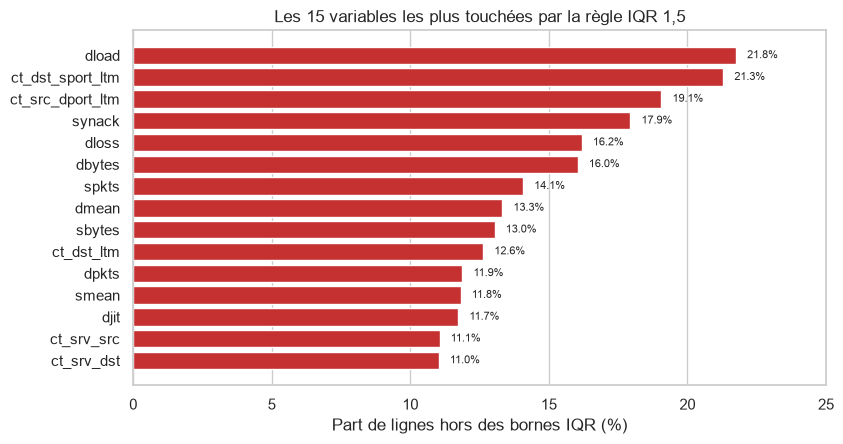

Taux médian d'outliers par variable : 9.9 %
Lignes avec au moins un outlier : 81.4 %


In [ ]:

q1 = train[numeric_features].quantile(0.25)
q3 = train[numeric_features].quantile(0.75)
iqr = q3 - q1
is_out = (train[numeric_features] < q1 - 1.5 * iqr) | (train[numeric_features] > q3 + 1.5 * iqr)

outlier_pct = (is_out.mean() * 100).sort_values(ascending=False)

top15 = outlier_pct.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8.6, 4.6))
bars = ax.barh(top15.index, top15.values, color="#c53030")
for r, v in zip(bars, top15.values):
    ax.text(v + 0.4, r.get_y() + r.get_height() / 2, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, top15.max() * 1.15)
ax.set_xlabel("Part de lignes hors des bornes IQR (%)")
ax.set_title("Les 15 variables les plus touchées par la règle IQR 1,5")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Taux médian d'outliers par variable : {outlier_pct.median():.1f} %")
print(f"Lignes avec au moins un outlier : {is_out.any(axis=1).mean() * 100:.1f} %")

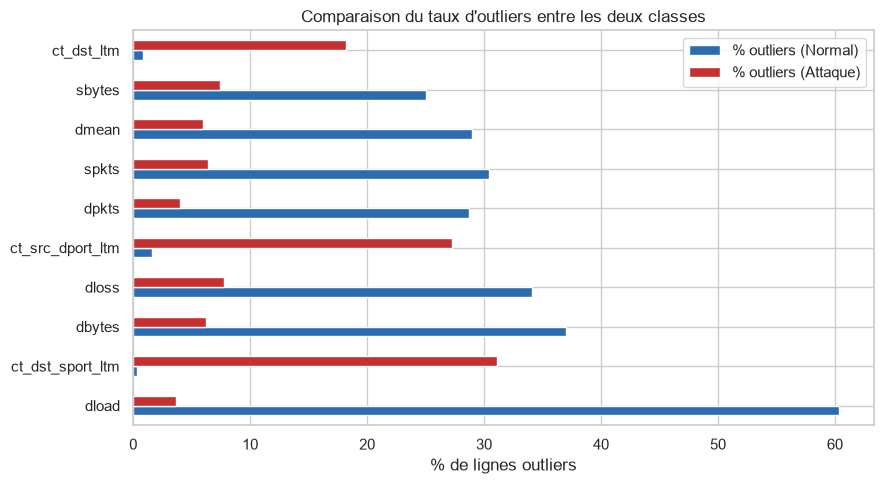

In [14]:
is_attack = train["label"] == 1

by_class = pd.DataFrame({
    "% outliers (Normal)": is_out[~is_attack].mean() * 100,
    "% outliers (Attaque)": is_out[is_attack].mean() * 100,
})

by_class["écart"] = (
    by_class["% outliers (Attaque)"] -
    by_class["% outliers (Normal)"]
)

top = by_class["écart"].abs().nlargest(10).index

by_class.loc[top, ["% outliers (Normal)", "% outliers (Attaque)"]].plot.barh(
    figsize=(9, 5), color=["#2b6cb0", "#c53030"]
)

plt.title("Comparaison du taux d'outliers entre les deux classes")
plt.xlabel("% de lignes outliers")
plt.tight_layout()
plt.show()

## 6. Trafic normal vs attaque

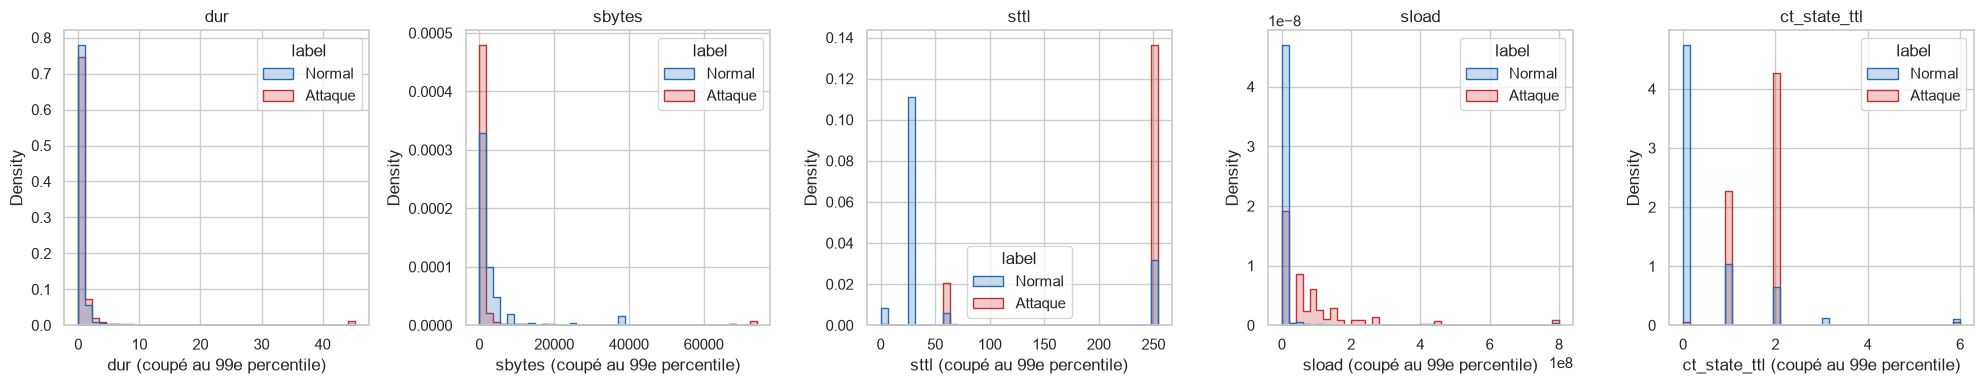

In [15]:
key_features = ["dur", "sbytes", "sttl", "sload", "ct_state_ttl"]
labels = train["label"].map({0: "Normal", 1: "Attaque"})

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, feature in zip(axes, key_features):
    q99 = train[feature].quantile(0.99)
    sns.histplot(x=train[feature].clip(upper=q99), hue=labels, stat="density", common_norm=False,
                 element="step", bins=40, palette={"Normal": "#2b6cb0", "Attaque": "#c53030"}, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel(f"{feature} (coupé au 99e percentile)")
plt.tight_layout()
plt.show()

## 7. Corrélations

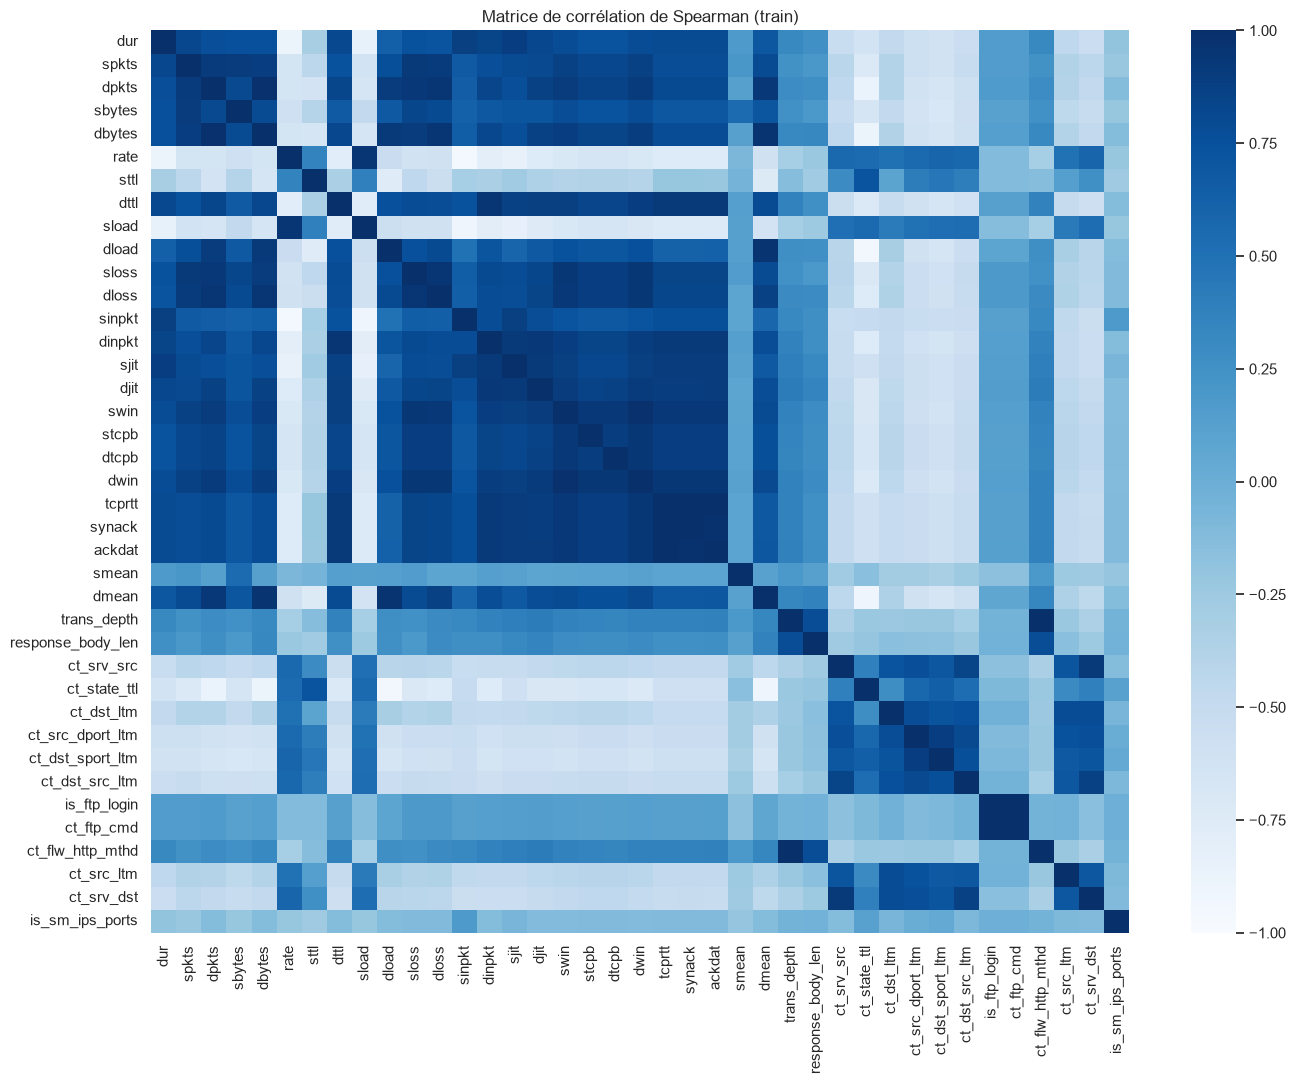

In [16]:
corr = train[numeric_features].corr(method="spearman")

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="Blues", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation de Spearman (train)")
plt.tight_layout()
plt.show()

In [17]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("corr").reset_index()
pairs.columns = ["feature_1", "feature_2", "corr"]
high_pairs = pairs[pairs["corr"].abs() > 0.95].sort_values("corr", key=abs, ascending=False)
display(high_pairs.round(3))

redundant = [c for c in upper.columns if (upper[c].abs() > 0.95).any()]
print("Features redondantes candidates à la suppression :", redundant)

,feature_1,feature_2,corr
1321,is_ftp_login,ct_ftp_cmd,1.000
1010,trans_depth,ct_flw_http_mthd,1.000
801,tcprtt,synack,0.997
802,tcprtt,ackdat,0.994
643,swin,dwin,0.990
82,dpkts,dbytes,0.990
841,synack,ackdat,0.984
180,dbytes,dmean,0.963
375,dload,dmean,0.963
203,rate,sload,0.960


Features redondantes candidates à la suppression : ['dbytes', 'sload', 'dloss', 'sinpkt', 'dinpkt', 'dwin', 'synack', 'ackdat', 'dmean', 'ct_ftp_cmd', 'ct_flw_http_mthd']


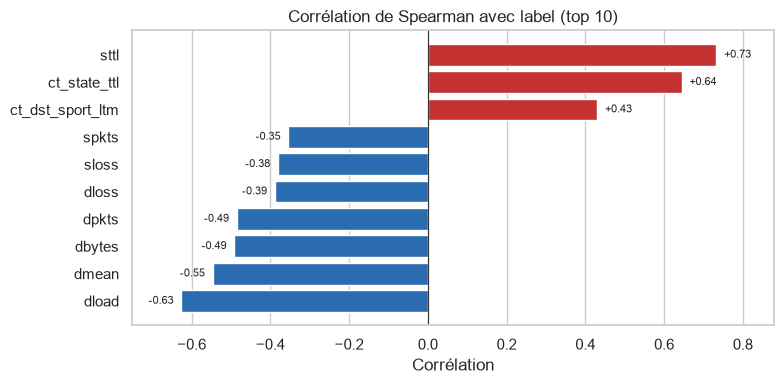

In [18]:
label_corr = train[numeric_features].corrwith(train["label"], method="spearman")
top10 = label_corr.reindex(label_corr.abs().sort_values(ascending=False).head(10).index).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(top10.index, top10.values,
               color=["#c53030" if v > 0 else "#2b6cb0" for v in top10.values])
ax.axvline(0, color="#333333", lw=0.8)
for r, v in zip(bars, top10.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), r.get_y() + r.get_height() / 2,
            f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.set_xlim(top10.min() * 1.2, top10.max() * 1.2)
ax.set_title("Corrélation de Spearman avec label (top 10)")
ax.set_xlabel("Corrélation")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()